# Student Performance & Learning Analytics
Major Project - Data Science Track

**About the data.** This project uses a **synthetic** student dataset produced by the code in section 1 (fixed random seed, so it is identical on every run). Relationships such as attendance and study time raising scores were built into the generator, so the findings below demonstrate the analysis workflow, not discoveries about real students. The generator also injects realistic mess (inconsistent text, duplicates, impossible values, missing values) so the cleaning pipeline has genuine work to do.

**Workflow:** dataset, cleaning pipeline, exploratory analysis, attendance analysis, subject-wise analysis, correlation analysis, visualizations (saved to `charts/`), feature engineering, prediction model, model evaluation, conclusions.

| Column | Meaning |
|---|---|
| StudentID | Unique student identifier |
| Gender | Male or Female |
| AttendancePct | Percentage of classes attended |
| StudyHours | Weekly study hours |
| PreviousScore | Score in the previous exam (%) |
| ParentalSupport | Low, Medium or High |
| ExtraClasses | Whether the student attends extra classes (Yes/No) |
| Maths, Science, English, SocialStudies, Computer | Subject scores out of 100 |
| AverageScore | Mean of the five subject scores (the value the model predicts) |
| AtRisk | True when AverageScore is below 55 |

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.linear_model import LinearRegression
from sklearn.dummy import DummyRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

sns.set_theme(style="whitegrid")
os.makedirs("charts", exist_ok=True)

SEED = 42
SUBJECTS = ["Maths", "Science", "English", "SocialStudies", "Computer"]
AT_RISK_BELOW = 55

## 1. Student dataset

The raw file has 612 rows. Problems found in it:

- 12 exact duplicate rows
- Gender written 8 different ways, parental support 12 ways, extra classes 8 ways
- Missing values: 31 in attendance, 24 in study hours, 18 in parental support, and 6 in each subject score
- Impossible values: attendance stored as a fraction, attendance above 100, negative study hours, and subject scores outside 0-100

In [2]:
def make_raw_students(n=600, seed=42):
    """Synthetic student records, deliberately made messy like real exports."""
    rng = np.random.default_rng(seed)

    gender = rng.choice(["Male", "Female"], n)
    attendance = np.clip(rng.normal(82, 12, n), 40, 100)
    study = np.clip(rng.gamma(3.0, 2.2, n), 0, 25)
    previous = np.clip(rng.normal(62, 14, n) + 0.25 * (attendance - 82), 25, 98)
    support = rng.choice(["Low", "Medium", "High"], n, p=[0.25, 0.45, 0.30])
    extra = rng.choice(["Yes", "No"], n, p=[0.4, 0.6])

    support_eff = pd.Series(support).map({"Low": 0.0, "Medium": 2.5, "High": 5.0}).to_numpy()
    extra_eff = np.where(extra == "Yes", 3.0, 0.0)
    low_att_penalty = -0.35 * np.maximum(0, 65 - attendance)

    base = (10 + 0.22 * attendance + 7.0 * np.log1p(study) + 0.32 * previous
            + support_eff + extra_eff + low_att_penalty + rng.normal(0, 4, n))

    offset = {"Maths": -4, "Science": -1, "English": 3, "SocialStudies": 1, "Computer": 2}
    study_sens = {"Maths": 0.5, "Science": 0.3, "English": -0.3, "SocialStudies": 0.0, "Computer": 0.2}
    scores = {s: np.clip(base + offset[s] + study_sens[s] * (study - 6.6) + rng.normal(0, 5, n), 0, 100)
              for s in SUBJECTS}

    df = pd.DataFrame({
        "StudentID": [f"S{i:04d}" for i in range(1, n + 1)],
        "Gender": gender,
        "AttendancePct": attendance.round(1),
        "StudyHours": study.round(1),
        "PreviousScore": previous.round(1),
        "ParentalSupport": support,
        "ExtraClasses": extra,
        **{s: scores[s].round(1) for s in SUBJECTS},
    })

    # ---- inject the kinds of problems real data has ----
    noise = np.random.default_rng(seed + 1)

    def messy(col, options):
        df[col] = [str(noise.choice(options[v])) if noise.random() < 0.35 else v for v in df[col]]

    messy("Gender", {"Male": ["male", "M", " Male"], "Female": ["female", "F", "Female "]})
    messy("ParentalSupport", {"Low": ["low", "LOW", " Low"],
                              "Medium": ["medium", "MEDIUM", "Medium "],
                              "High": ["high", "HIGH", " High"]})
    messy("ExtraClasses", {"Yes": ["yes", "Y", "YES"], "No": ["no", "N", "NO"]})

    order = noise.permutation(n)
    pos = [0]

    def take(k):
        chunk = order[pos[0]:pos[0] + k]
        pos[0] += k
        return chunk

    for i in take(8):                       # attendance stored as a fraction (0.85 instead of 85)
        df.loc[i, "AttendancePct"] = round(df.loc[i, "AttendancePct"] / 100, 3)
    for i in take(6):                       # impossible attendance above 100
        df.loc[i, "AttendancePct"] = round(100 + noise.uniform(1, 15), 1)
    df.loc[take(30), "AttendancePct"] = np.nan
    for i in take(5):                       # negative study hours
        df.loc[i, "StudyHours"] = -round(noise.uniform(1, 5), 1)
    df.loc[take(24), "StudyHours"] = np.nan
    df.loc[take(18), "ParentalSupport"] = None
    for s in SUBJECTS:                      # missing subject scores
        df.loc[take(6), s] = np.nan
    for i in take(4):                       # scores outside 0-100
        df.loc[i, str(noise.choice(SUBJECTS))] = float(noise.choice([105, 110, 120, 150, -5, -10]))

    duplicates = df.sample(12, random_state=seed)
    return pd.concat([df, duplicates]).sample(frac=1, random_state=seed).reset_index(drop=True)


raw = make_raw_students()
raw.to_csv("raw_students.csv", index=False)
print("Saved raw_students.csv")
raw.head(10)

Saved raw_students.csv


,StudentID,Gender,AttendancePct,StudyHours,PreviousScore,ParentalSupport,ExtraClasses,Maths,Science,English,SocialStudies,Computer
0,S0082,Male,92.1,2.2,64.8,low,No,NaN,50.5,56.1,61.1,55.5
1,S0219,Male,100.0,9.0,82.5,LOW,No,63.2,81.6,78.0,70.5,69.5
2,S0056,Male,87.0,5.7,52.8,Medium,yes,60.7,54.6,53.1,68.8,55.4
3,S0111,Male,88.4,5.0,51.5,Medium,No,56.1,58.2,70.8,69.9,62.2
4,S0265,Female,NaN,5.1,50.5,High,Yes,62.0,71.1,73.4,66.3,70.7
5,S0156,Female,97.8,5.5,73.7,Low,N,50.0,66.3,61.1,59.8,64.2
6,S0484,female,98.3,8.7,85.8,Medium,Yes,78.7,75.4,75.9,88.3,74.4
7,S0322,male,88.5,5.5,79.5,medium,NO,68.8,72.5,76.1,71.5,70.6
8,S0583,Male,85.3,10.1,38.2,High,No,57.5,60.1,63.8,71.0,61.6
9,S0292,Male,86.4,2.0,46.9,Low,No,36.0,42.1,47.6,54.1,51.6


In [3]:
print("Shape:", raw.shape)
print("Duplicate rows:", raw.duplicated().sum())
print()
print("Missing values per column")
print(raw.isna().sum())

Shape: (612, 12)
Duplicate rows: 12

Missing values per column
StudentID           0
Gender              0
AttendancePct      31
StudyHours         24
PreviousScore       0
ParentalSupport    18
ExtraClasses        0
Maths               6
Science             6
English             6
SocialStudies       6
Computer            6
dtype: int64


In [4]:
# the same category written many different ways
print(raw["Gender"].value_counts())
print()
print(raw["ParentalSupport"].value_counts(dropna=False))

Gender
Male       211
Female     186
Female      51
male        48
F           36
female      27
M           27
 Male       26
Name: count, dtype: int64

ParentalSupport
Medium     174
Low        109
High       103
Medium      34
MEDIUM      32
medium      28
 High       23
 Low        23
low         21
HIGH        18
NaN         18
LOW         16
high        13
Name: count, dtype: int64


In [5]:
print("Attendance stored as a fraction (<= 1):", (raw["AttendancePct"] <= 1).sum())
print("Attendance above 100:", (raw["AttendancePct"] > 100).sum())
print("Negative study hours:", (raw["StudyHours"] < 0).sum())
print("Subject scores outside 0-100:", ((raw[SUBJECTS] < 0) | (raw[SUBJECTS] > 100)).sum().sum())

Attendance stored as a fraction (<= 1): 8
Attendance above 100: 6
Negative study hours: 5
Subject scores outside 0-100: 4


## 2. Data cleaning pipeline

The pipeline is a single function, so it can be re-run on new data, and it returns a log of every change. Decisions made:

- **Text** is trimmed, lower-cased and mapped to one standard spelling per category.
- **Duplicates** are removed by StudentID.
- **Attendance stored as a fraction** (8 rows) is rescaled to a percentage, because 0.85 is clearly 85%.
- **Impossible values** (attendance above 100, negative study hours, scores outside 0-100) are treated as missing rather than clipped, since the true value is unknown.
- **Rows missing a subject score** (34 rows, 5.7% of students) are dropped. The prediction target is built from these scores, so filling them in would put guessed values into what the model has to predict.
- **Remaining gaps in input columns** are filled with the median (numbers) or most common value (categories).

**A limitation worth knowing:** the fill values are calculated on the whole dataset before it is split into training and testing data. With at most 6.4% of any column filled, the effect on the evaluation is small, but in a production pipeline the fill values would be learned from the training data only.

After cleaning, the dataset has 566 rows and no missing values, and the checks below confirm it.

In [6]:
def clean_students(raw):
    """Cleaning pipeline: returns the cleaned frame and a log of every change made."""
    df = raw.copy()
    log = {"rows_raw": len(raw)}

    # 1. standardise text categories
    for col in ["Gender", "ParentalSupport", "ExtraClasses"]:
        df[col] = df[col].str.strip().str.lower()
    df["Gender"] = df["Gender"].map({"male": "Male", "m": "Male", "female": "Female", "f": "Female"})
    df["ParentalSupport"] = df["ParentalSupport"].map({"low": "Low", "medium": "Medium", "high": "High"})
    df["ExtraClasses"] = df["ExtraClasses"].map({"yes": "Yes", "y": "Yes", "no": "No", "n": "No"})

    # 2. remove duplicate students
    before = len(df)
    df = df.drop_duplicates(subset="StudentID", keep="first")
    log["duplicates_removed"] = before - len(df)

    # 3. attendance stored as a fraction -> percentage
    fraction = df["AttendancePct"] <= 1
    log["attendance_fractions_rescaled"] = int(fraction.sum())
    df.loc[fraction, "AttendancePct"] = (df.loc[fraction, "AttendancePct"] * 100).round(1)

    # 4. impossible values -> missing
    too_high = df["AttendancePct"] > 100
    log["attendance_over_100_set_missing"] = int(too_high.sum())
    df.loc[too_high, "AttendancePct"] = np.nan

    negative = df["StudyHours"] < 0
    log["negative_study_hours_set_missing"] = int(negative.sum())
    df.loc[negative, "StudyHours"] = np.nan

    out_of_range = (df[SUBJECTS] < 0) | (df[SUBJECTS] > 100)
    log["scores_outside_0_100_set_missing"] = int(out_of_range.sum().sum())
    df[SUBJECTS] = df[SUBJECTS].mask(out_of_range)

    # 5. rows missing a subject score are dropped (the target is built from these scores,
    #    so filling them in would put guessed values into what the model must predict)
    before = len(df)
    df = df.dropna(subset=SUBJECTS)
    log["rows_dropped_missing_subject_score"] = before - len(df)

    # 6. fill remaining gaps in the input columns: median for numbers, most common value for categories
    for col in ["AttendancePct", "StudyHours", "PreviousScore"]:
        log["filled_" + col] = int(df[col].isna().sum())
        df[col] = df[col].fillna(df[col].median())
    for col in ["Gender", "ParentalSupport", "ExtraClasses"]:
        log["filled_" + col] = int(df[col].isna().sum())
        df[col] = df[col].fillna(df[col].mode()[0])

    log["rows_clean"] = len(df)
    return df.reset_index(drop=True), log


df, log = clean_students(raw)
pd.Series(log, name="count").to_frame()

,count
rows_raw,612
duplicates_removed,12
attendance_fractions_rescaled,8
attendance_over_100_set_missing,6
negative_study_hours_set_missing,5
scores_outside_0_100_set_missing,4
rows_dropped_missing_subject_score,34
filled_AttendancePct,36
filled_StudyHours,29
filled_PreviousScore,0


In [7]:
# checks that the cleaning worked - any failure stops the notebook here
assert df.isna().sum().sum() == 0
assert df["StudentID"].is_unique
assert df["Gender"].isin(["Male", "Female"]).all()
assert df["ParentalSupport"].isin(["Low", "Medium", "High"]).all()
assert df["ExtraClasses"].isin(["Yes", "No"]).all()
assert df["AttendancePct"].between(0, 100).all()
assert (df["StudyHours"] >= 0).all()
assert df[SUBJECTS].apply(lambda c: c.between(0, 100)).all().all()
print("All validation checks passed")
print("Rows:", len(raw), "->", len(df))

All validation checks passed
Rows: 612 -> 566


In [8]:
df["AverageScore"] = df[SUBJECTS].mean(axis=1).round(2)
df["AtRisk"] = df["AverageScore"] < AT_RISK_BELOW
df["AttendanceBand"] = pd.cut(df["AttendancePct"], bins=[0, 60, 75, 90, 100],
                               labels=["Below 60", "60-75", "75-90", "90-100"])

df.to_csv("cleaned_students.csv", index=False)
print("Saved cleaned_students.csv")
df.head()

Saved cleaned_students.csv


,StudentID,Gender,AttendancePct,StudyHours,PreviousScore,ParentalSupport,ExtraClasses,Maths,Science,English,SocialStudies,Computer,AverageScore,AtRisk,AttendanceBand
0,S0219,Male,100.00,9.0,82.5,Low,No,63.2,81.6,78.0,70.5,69.5,72.56,False,90-100
1,S0056,Male,87.00,5.7,52.8,Medium,Yes,60.7,54.6,53.1,68.8,55.4,58.52,False,75-90
2,S0111,Male,88.40,5.0,51.5,Medium,No,56.1,58.2,70.8,69.9,62.2,63.44,False,75-90
3,S0265,Female,81.75,5.1,50.5,High,Yes,62.0,71.1,73.4,66.3,70.7,68.70,False,75-90
4,S0156,Female,97.80,5.5,73.7,Low,No,50.0,66.3,61.1,59.8,64.2,60.28,False,90-100


## 3. Exploratory data analysis

**Interpretation.** Average scores centre on 64.5 with a standard deviation of 8.8, ranging from 36.5 to 88.0. 77 students (13.6%) fall below the at-risk cutoff of 55. The attendance histogram has a spike at the right edge because 35 students (6.2%) attended 100% of classes, which is the maximum possible.

Group averages show a clear gap for **parental support**: 61.4 for Low, 64.4 for Medium and 67.9 for High, a spread of 6.5 points. Students attending **extra classes** average 66.1 against 63.5 for those who do not (2.6 points). **Gender** shows essentially no difference (64.4 for female students, 64.6 for male). These are group averages and do not show cause and effect.

In [9]:
df[["AttendancePct", "StudyHours", "PreviousScore"] + SUBJECTS + ["AverageScore"]].describe().round(2)

,AttendancePct,StudyHours,PreviousScore,Maths,Science,English,SocialStudies,Computer,AverageScore
count,566.00,566.00,566.00,566.00,566.00,566.00,566.00,566.00,566.00
mean,81.00,6.37,62.19,59.85,63.36,67.65,65.34,66.24,64.49
std,11.27,3.56,14.46,10.34,10.04,9.69,9.88,9.84,8.84
min,46.40,0.30,25.00,32.60,33.90,35.20,35.00,37.90,36.54
25%,73.70,4.00,52.82,52.80,56.32,60.90,59.02,59.52,58.32
50%,81.75,5.80,61.65,59.70,63.20,68.05,64.85,65.95,64.24
75%,88.50,7.98,72.20,67.38,70.20,74.30,71.78,72.90,70.58
max,100.00,23.30,98.00,87.00,99.50,98.00,93.70,94.70,87.98


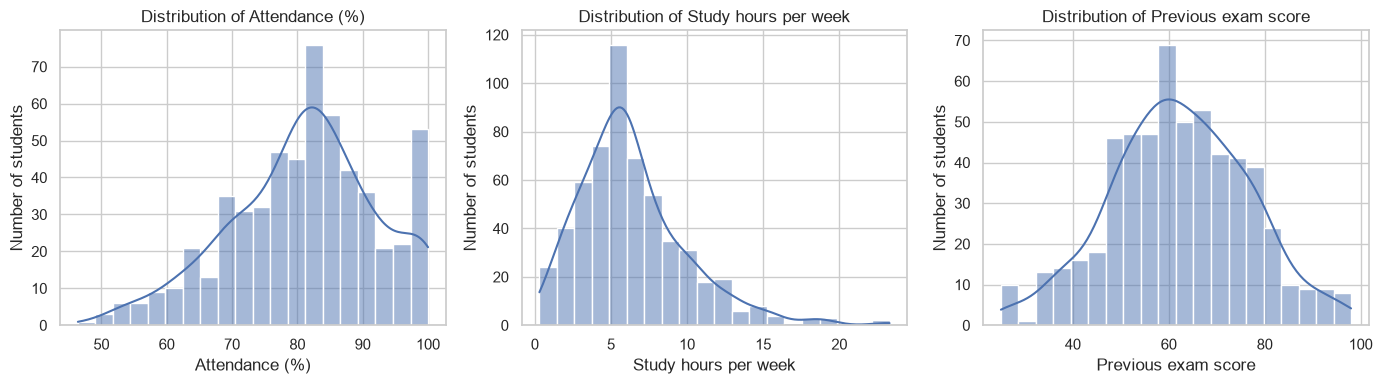

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, col, label in zip(axes,
                          ["AttendancePct", "StudyHours", "PreviousScore"],
                          ["Attendance (%)", "Study hours per week", "Previous exam score"]):
    sns.histplot(df[col], bins=20, kde=True, ax=ax)
    ax.set_title("Distribution of " + label)
    ax.set_xlabel(label)
    ax.set_ylabel("Number of students")
plt.tight_layout()
plt.savefig("charts/01_feature_distributions.png", dpi=150, bbox_inches="tight")
plt.show()

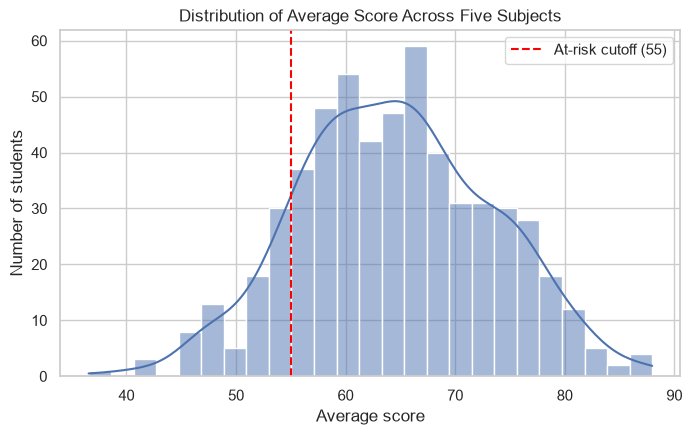

In [11]:
plt.figure(figsize=(8, 4.5))
sns.histplot(df["AverageScore"], bins=25, kde=True)
plt.axvline(AT_RISK_BELOW, color="red", linestyle="--", label="At-risk cutoff (" + str(AT_RISK_BELOW) + ")")
plt.title("Distribution of Average Score Across Five Subjects")
plt.xlabel("Average score")
plt.ylabel("Number of students")
plt.legend()
plt.savefig("charts/02_average_score_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

In [12]:
print(df["AtRisk"].value_counts())
print()
print("At-risk share: " + str(round(df["AtRisk"].mean() * 100, 1)) + "%")

AtRisk
False    489
True      77
Name: count, dtype: int64

At-risk share: 13.6%


In [13]:
order = ["Low", "Medium", "High"]
support_summary = (df.groupby("ParentalSupport")["AverageScore"].agg(["count", "mean"]).round(2)
                   .reindex(order))
extra_summary = df.groupby("ExtraClasses")["AverageScore"].agg(["count", "mean"]).round(2)
gender_summary = df.groupby("Gender")["AverageScore"].agg(["count", "mean"]).round(2)

print("By parental support"); print(support_summary); print()
print("By extra classes"); print(extra_summary); print()
print("By gender"); print(gender_summary)

By parental support
                 count   mean
ParentalSupport              
Low                156  61.40
Medium             262  64.39
High               148  67.92

By extra classes
              count   mean
ExtraClasses              
No              347  63.48
Yes             219  66.09

By gender
        count   mean
Gender              
Female    281  64.42
Male      285  64.56


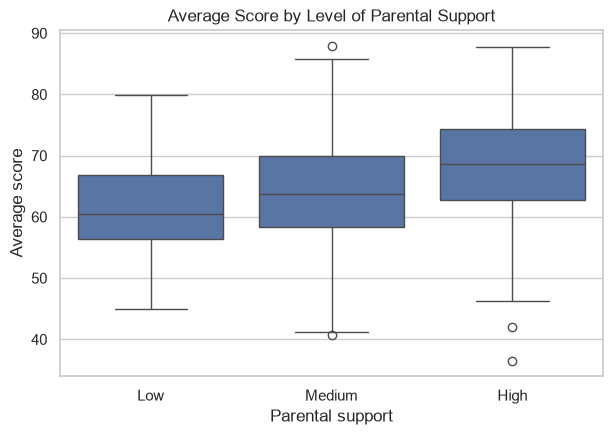

In [14]:
plt.figure(figsize=(7, 4.5))
sns.boxplot(data=df, x="ParentalSupport", y="AverageScore", order=["Low", "Medium", "High"])
plt.title("Average Score by Level of Parental Support")
plt.xlabel("Parental support")
plt.ylabel("Average score")
plt.savefig("charts/03_score_by_parental_support.png", dpi=150, bbox_inches="tight")
plt.show()

## 4. Attendance analysis

**Interpretation.** Average score rises with every attendance band, from 55.2 for students below 60% to 69.8 for those at 90-100%. The share of at-risk students falls from 48.1% in the lowest band to 22.0%, 9.9% and 5.9% in the higher ones. The overall correlation between attendance and average score is 0.43.

The relationship is **not the same across the whole range.** Below 65% attendance each extra point of attendance goes with about 0.82 points of average score, against about 0.34 points at or above 65%. Of the 55 students below 65%, 38.2% are at risk, compared with 11.0% of the rest. Caution: only 27 students are in the lowest band and 55 below 65%, so the slope for the low group is a noisy estimate, and none of this proves attendance causes the difference.

In [15]:
att_band = df.groupby("AttendanceBand", observed=True).agg(
    students=("StudentID", "count"),
    avg_score=("AverageScore", "mean"),
    at_risk_pct=("AtRisk", "mean"),
)
att_band["avg_score"] = att_band["avg_score"].round(2)
att_band["at_risk_pct"] = (att_band["at_risk_pct"] * 100).round(1)
att_band

,students,avg_score,at_risk_pct
AttendanceBand,,,
Below 60,27,55.22,48.1
60-75,127,60.33,22.0
75-90,293,64.97,9.9
90-100,119,69.85,5.9


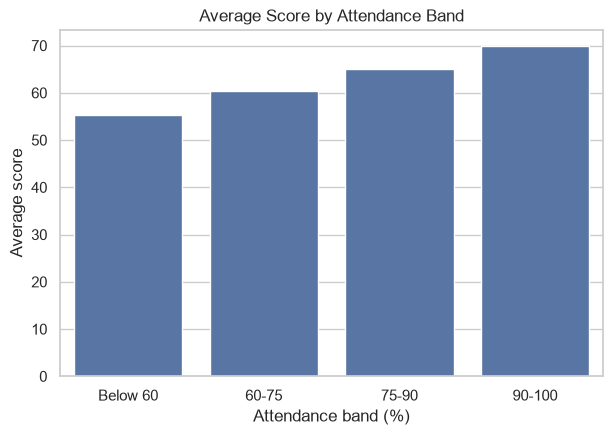

In [16]:
plt.figure(figsize=(7, 4.5))
sns.barplot(data=att_band.reset_index(), x="AttendanceBand", y="avg_score")
plt.title("Average Score by Attendance Band")
plt.xlabel("Attendance band (%)")
plt.ylabel("Average score")
plt.savefig("charts/04_score_by_attendance_band.png", dpi=150, bbox_inches="tight")
plt.show()

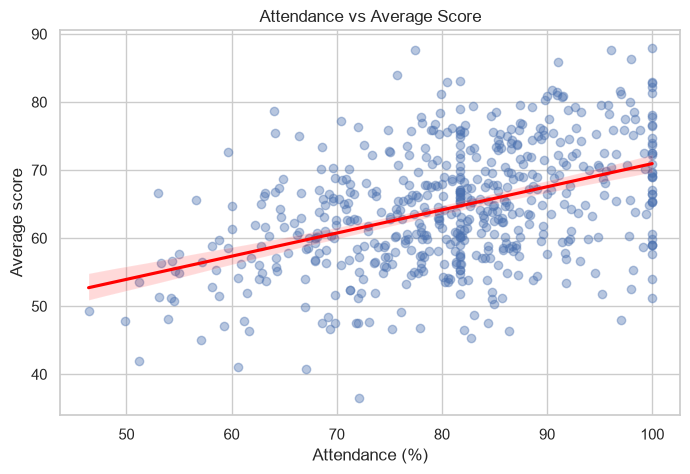

Correlation: 0.43


In [17]:
att_corr = df["AttendancePct"].corr(df["AverageScore"])

plt.figure(figsize=(8, 5))
sns.regplot(data=df, x="AttendancePct", y="AverageScore",
            scatter_kws={"alpha": 0.4}, line_kws={"color": "red"})
plt.title("Attendance vs Average Score")
plt.xlabel("Attendance (%)")
plt.ylabel("Average score")
plt.savefig("charts/05_attendance_vs_score.png", dpi=150, bbox_inches="tight")
plt.show()

print("Correlation:", round(att_corr, 2))

In [18]:
# is the relationship the same across the whole attendance range?
CUTOFF = 65
below_cutoff = df[df["AttendancePct"] < CUTOFF]
above_cutoff = df[df["AttendancePct"] >= CUTOFF]

slope_low = np.polyfit(below_cutoff["AttendancePct"], below_cutoff["AverageScore"], 1)[0]
slope_high = np.polyfit(above_cutoff["AttendancePct"], above_cutoff["AverageScore"], 1)[0]

print("Students below", CUTOFF, "% attendance:", len(below_cutoff))
print("Score change per extra attendance point, below cutoff:", round(slope_low, 2))
print("Score change per extra attendance point, at/above cutoff:", round(slope_high, 2))
print("At-risk share below cutoff:", round(below_cutoff["AtRisk"].mean() * 100, 1), "%")
print("At-risk share at/above cutoff:", round(above_cutoff["AtRisk"].mean() * 100, 1), "%")

Students below 65 % attendance: 55
Score change per extra attendance point, below cutoff: 0.82
Score change per extra attendance point, at/above cutoff: 0.34
At-risk share below cutoff: 38.2 %
At-risk share at/above cutoff: 11.0 %


## 5. Subject-wise performance analysis

**Interpretation.** English is the strongest subject with an average of 67.7 and Maths the weakest at 59.9, a gap of 7.8 points. Spread is similar across subjects (standard deviation 9.7 to 10.3).

At the student level, Maths is the lowest-scoring subject for 307 students (54.2%) and the highest for only 20 (3.5%), while English is the top subject for 232 students (41.0%). So Maths is a weakness for the whole group, not just a few individuals.

Study hours relate most strongly to Maths (r = 0.51), which is also the weakest subject, and least to English (r = 0.25). Previous score (0.46 to 0.52) and attendance (0.37 to 0.41) relate to every subject at a similar level.

In [19]:
subject_stats = df[SUBJECTS].agg(["mean", "median", "std", "min", "max"]).T.round(2)
subject_stats = subject_stats.sort_values("mean", ascending=False)
subject_stats

,mean,median,std,min,max
English,67.65,68.05,9.69,35.2,98.0
Computer,66.24,65.95,9.84,37.9,94.7
SocialStudies,65.34,64.85,9.88,35.0,93.7
Science,63.36,63.20,10.04,33.9,99.5
Maths,59.85,59.70,10.34,32.6,87.0


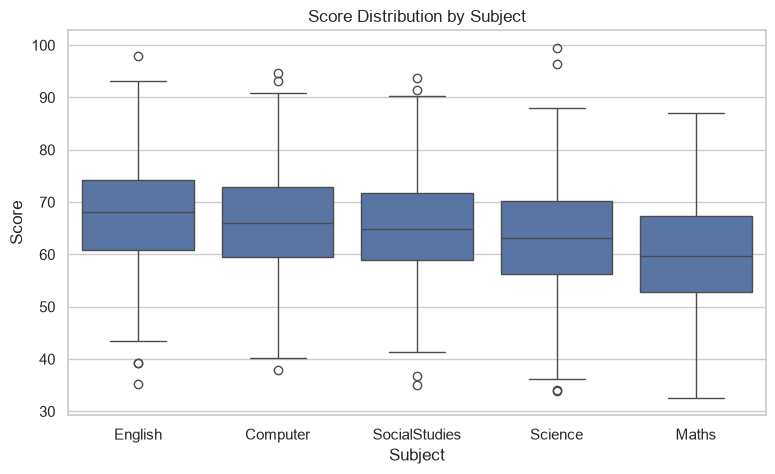

In [20]:
plt.figure(figsize=(9, 5))
sns.boxplot(data=df.melt(value_vars=SUBJECTS, var_name="Subject", value_name="Score"),
            x="Subject", y="Score", order=subject_stats.index)
plt.title("Score Distribution by Subject")
plt.xlabel("Subject")
plt.ylabel("Score")
plt.savefig("charts/06_subject_score_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

In [21]:
best = df[SUBJECTS].idxmax(axis=1).value_counts()
worst = df[SUBJECTS].idxmin(axis=1).value_counts()

strengths = pd.DataFrame({"best_subject_for": best, "weakest_subject_for": worst}).fillna(0).astype(int)
strengths["best_pct"] = (strengths["best_subject_for"] / len(df) * 100).round(1)
strengths["weakest_pct"] = (strengths["weakest_subject_for"] / len(df) * 100).round(1)
strengths.sort_values("best_subject_for", ascending=False)

,best_subject_for,weakest_subject_for,best_pct,weakest_pct
English,232,43,41.0,7.6
Computer,143,37,25.3,6.5
SocialStudies,108,74,19.1,13.1
Science,63,105,11.1,18.6
Maths,20,307,3.5,54.2


In [22]:
# how strongly each factor relates to each subject
subject_drivers = pd.DataFrame({
    "Attendance": df[SUBJECTS].corrwith(df["AttendancePct"]),
    "StudyHours": df[SUBJECTS].corrwith(df["StudyHours"]),
    "PreviousScore": df[SUBJECTS].corrwith(df["PreviousScore"]),
}).round(2)
subject_drivers

,Attendance,StudyHours,PreviousScore
Maths,0.37,0.51,0.46
Science,0.38,0.45,0.48
English,0.38,0.25,0.52
SocialStudies,0.41,0.36,0.48
Computer,0.39,0.39,0.48


## 6. Correlation analysis

**Interpretation.** Of the three numeric inputs, previous score has the strongest correlation with average score (0.54), then study hours (0.45) and attendance (0.43). The five subjects correlate with each other between 0.70 and 0.77, so a student who is strong in one subject tends to be strong in the others, and average score correlates 0.86 to 0.90 with every subject.

The inputs are almost independent of each other: study hours and attendance correlate at 0.05, previous score and study hours at 0.01, and previous score and attendance at 0.18. That means each one adds separate information. Correlation measures linear association only and does not show cause.

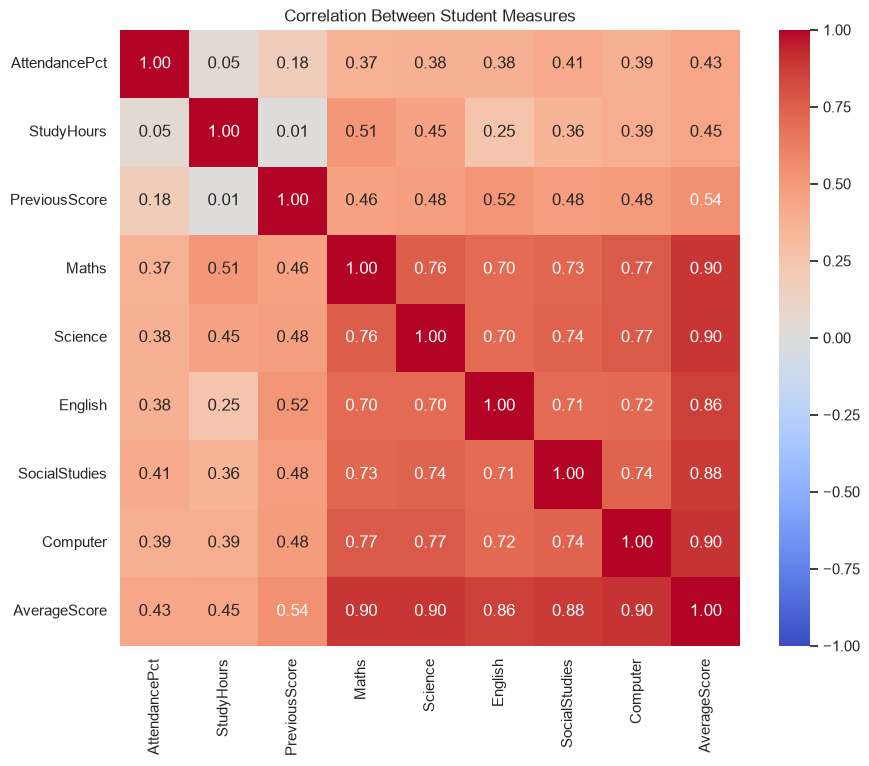

In [23]:
corr_cols = ["AttendancePct", "StudyHours", "PreviousScore"] + SUBJECTS + ["AverageScore"]
corr = df[corr_cols].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation Between Student Measures")
plt.savefig("charts/07_correlation_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

In [24]:
avg_corr = corr["AverageScore"].drop(["AverageScore"] + SUBJECTS).sort_values(ascending=False).round(2)
avg_corr

PreviousScore    0.54
StudyHours       0.45
AttendancePct    0.43
Name: AverageScore, dtype: float64

## 7. Student performance visualizations

Every chart is saved to the `charts/` folder as it is drawn. The charts so far cover feature distributions, the average score distribution, score by parental support, score by attendance band, attendance against score, score distribution by subject, and the correlation heatmap. The study-hours chart and the model charts follow in sections 8 to 10.

## 8. Feature engineering

Three kinds of feature are created:

- **Encodings:** parental support becomes an ordered score (Low 0, Medium 1, High 2), and extra classes and gender become 0/1 flags.
- **LogStudyHours:** the table above shows diminishing returns. The score gained per extra study hour falls from 2.88 points (between the 0-2 and 2-4 hour groups) to 0.45 points (between the 10-15 and 15-25 hour groups), so a log transform fits the shape better than a straight line.
- **AttendanceShortfall:** how far attendance falls below 65%, which captures the steeper slope seen in section 4.

The new features correlate with average score as expected: LogStudyHours 0.47 (against 0.45 for raw study hours) and AttendanceShortfall -0.29. The subject scores are deliberately **not** used as features: the average is calculated from them, so a model using them would be reading the answer instead of predicting it.

In [25]:
df["SupportScore"] = df["ParentalSupport"].map({"Low": 0, "Medium": 1, "High": 2})
df["ExtraClassesFlag"] = (df["ExtraClasses"] == "Yes").astype(int)
df["GenderFlag"] = (df["Gender"] == "Female").astype(int)

df[["ParentalSupport", "SupportScore", "ExtraClasses", "ExtraClassesFlag", "Gender", "GenderFlag"]].head()

,ParentalSupport,SupportScore,ExtraClasses,ExtraClassesFlag,Gender,GenderFlag
0,Low,0,No,0,Male,0
1,Medium,1,Yes,1,Male,0
2,Medium,1,No,0,Male,0
3,High,2,Yes,1,Female,1
4,Low,0,No,0,Female,1


In [26]:
# does more study time always give the same extra benefit?
study_bins = pd.cut(df["StudyHours"], bins=[0, 2, 4, 6, 8, 10, 15, 25])
study_curve = df.groupby(study_bins, observed=True)["AverageScore"].agg(["count", "mean"]).round(2)

# midpoint of each group, and the score gained per extra hour of study between neighbouring groups
study_curve["midpoint"] = [interval.mid for interval in study_curve.index]
study_curve["gain_per_extra_hour"] = (study_curve["mean"].diff() / study_curve["midpoint"].diff()).round(2)
study_curve

,count,mean,midpoint,gain_per_extra_hour
StudyHours,,,,
"(0, 2]",42,55.32,1.0,NaN
"(2, 4]",103,61.07,3.0,2.88
"(4, 6]",168,63.81,5.0,1.37
"(6, 8]",116,65.82,7.0,1.00
"(8, 10]",54,67.55,9.0,0.87
"(10, 15]",68,70.29,12.5,0.78
"(15, 25]",15,73.68,20.0,0.45


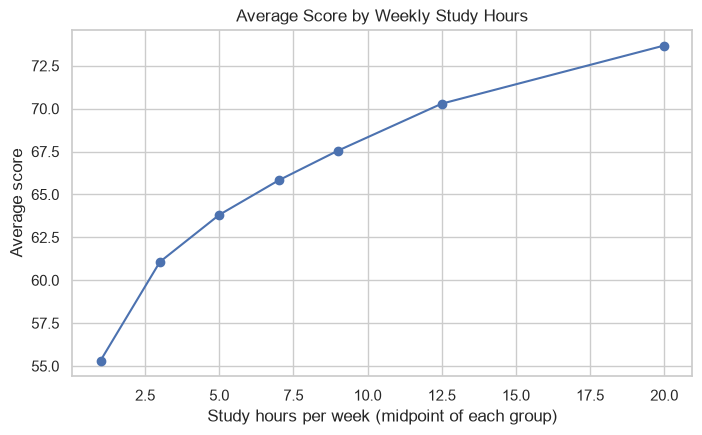

In [27]:
plt.figure(figsize=(8, 4.5))
plt.plot(study_curve["midpoint"], study_curve["mean"], marker="o")
plt.title("Average Score by Weekly Study Hours")
plt.xlabel("Study hours per week (midpoint of each group)")
plt.ylabel("Average score")
plt.savefig("charts/08_score_by_study_hours.png", dpi=150, bbox_inches="tight")
plt.show()

In [28]:
# diminishing returns on study time -> log transform
df["LogStudyHours"] = np.log1p(df["StudyHours"])

# the extra drop in scores below the attendance cutoff -> shortfall feature
df["AttendanceShortfall"] = (CUTOFF - df["AttendancePct"]).clip(lower=0)

df[["StudyHours", "LogStudyHours", "AttendancePct", "AttendanceShortfall"]].head()

,StudyHours,LogStudyHours,AttendancePct,AttendanceShortfall
0,9.0,2.302585,100.00,0.0
1,5.7,1.902108,87.00,0.0
2,5.0,1.791759,88.40,0.0
3,5.1,1.808289,81.75,0.0
4,5.5,1.871802,97.80,0.0


In [29]:
feature_corr = df[["AttendancePct", "AttendanceShortfall", "StudyHours", "LogStudyHours",
                   "PreviousScore", "SupportScore", "ExtraClassesFlag", "GenderFlag"]
                  ].corrwith(df["AverageScore"]).round(2).sort_values(ascending=False)
feature_corr

PreviousScore          0.54
LogStudyHours          0.47
StudyHours             0.45
AttendancePct          0.43
SupportScore           0.27
ExtraClassesFlag       0.14
GenderFlag            -0.01
AttendanceShortfall   -0.29
dtype: float64

In [30]:
df.to_csv("students_with_features.csv", index=False)
print("Saved students_with_features.csv")

Saved students_with_features.csv


## 9. Prediction model

The target is each student's average score, so linear regression is the natural starting model. The data is split once, 80% for training (452 students) and 20% for testing (114 students), and the test students are not used until the final evaluation. Three models are compared on the same split: a baseline that always predicts the average, linear regression on the original features, and linear regression with the engineered features.

In [31]:
RAW_FEATURES = ["AttendancePct", "StudyHours", "PreviousScore",
                "SupportScore", "ExtraClassesFlag", "GenderFlag"]
ENGINEERED_FEATURES = ["AttendancePct", "AttendanceShortfall", "LogStudyHours", "PreviousScore",
                       "SupportScore", "ExtraClassesFlag", "GenderFlag"]

# the subject scores themselves are NOT features: AverageScore is calculated from them,
# so using them would let the model read the answer instead of predicting it
X_train, X_test, y_train, y_test = train_test_split(
    df[sorted(set(RAW_FEATURES + ENGINEERED_FEATURES))], df["AverageScore"],
    test_size=0.2, random_state=SEED)

print("Training rows:", len(X_train))
print("Testing rows: ", len(X_test))

Training rows: 452
Testing rows:  114


In [32]:
def evaluate(model, features):
    model.fit(X_train[features], y_train)
    pred = model.predict(X_test[features])
    cv_r2 = cross_val_score(model, X_train[features], y_train, cv=5, scoring="r2").mean()
    return {
        "R2 (test)": r2_score(y_test, pred),
        "MAE (test)": mean_absolute_error(y_test, pred),
        "RMSE (test)": np.sqrt(mean_squared_error(y_test, pred)),
        "R2 (5-fold CV on train)": cv_r2,
    }, pred

baseline_scores, _ = evaluate(DummyRegressor(strategy="mean"), RAW_FEATURES)
raw_scores, raw_pred = evaluate(LinearRegression(), RAW_FEATURES)
eng_scores, eng_pred = evaluate(LinearRegression(), ENGINEERED_FEATURES)

results = pd.DataFrame({
    "Baseline (predict the mean)": baseline_scores,
    "Linear regression - original features": raw_scores,
    "Linear regression - engineered features": eng_scores,
}).T.round(3)
results

,R2 (test),MAE (test),RMSE (test),R2 (5-fold CV on train)
Baseline (predict the mean),-0.002,6.643,8.296,-0.025
Linear regression - original features,0.694,3.655,4.582,0.662
Linear regression - engineered features,0.721,3.430,4.379,0.689


In [33]:
# coefficients on standardised features, so their sizes can be compared fairly
scaler = StandardScaler().fit(X_train[ENGINEERED_FEATURES])
final_model = LinearRegression().fit(scaler.transform(X_train[ENGINEERED_FEATURES]), y_train)

coef_table = pd.DataFrame({"feature": ENGINEERED_FEATURES, "coefficient": final_model.coef_})
coef_table = coef_table.sort_values("coefficient", key=abs, ascending=False).round(2)
coef_table

,feature,coefficient
3,PreviousScore,4.31
2,LogStudyHours,3.95
0,AttendancePct,2.89
4,SupportScore,2.10
5,ExtraClassesFlag,1.40
1,AttendanceShortfall,-0.49
6,GenderFlag,-0.46


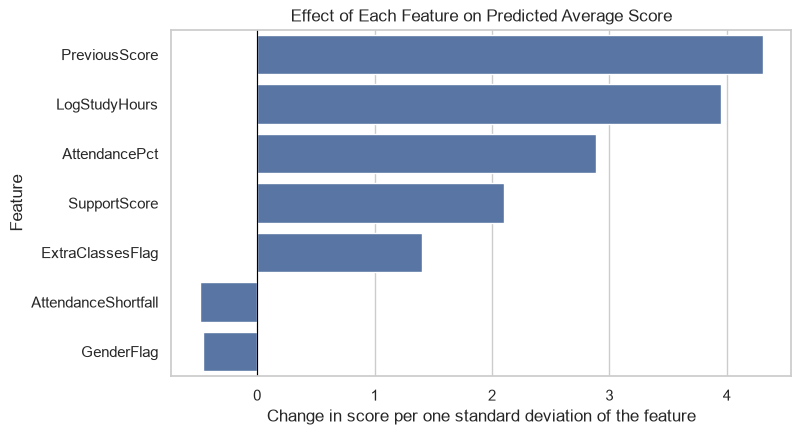

In [34]:
plt.figure(figsize=(8, 4.5))
sns.barplot(data=coef_table, x="coefficient", y="feature")
plt.axvline(0, color="black", linewidth=0.8)
plt.title("Effect of Each Feature on Predicted Average Score")
plt.xlabel("Change in score per one standard deviation of the feature")
plt.ylabel("Feature")
plt.savefig("charts/09_model_coefficients.png", dpi=150, bbox_inches="tight")
plt.show()

## 10. Model evaluation

**Interpretation.** The baseline scores an R-squared of -0.002 (essentially zero, as expected for a model that ignores the inputs) with an average error of 6.64 points. Linear regression on the original features reaches an R-squared of 0.694 and an average error (MAE) of 3.65. Adding the engineered features improves this to an R-squared of 0.721, an MAE of 3.43 and an RMSE of 4.38. The cross-validated R-squared rises by a similar amount (0.662 to 0.689), which suggests the improvement of about 0.027 is real but modest.

Predictions are typically within about 3.4 points of the true average. On standardized features the largest effects are previous score (4.31), log study hours (3.95), attendance (2.89), parental support (2.10) and extra classes (1.40). Gender (-0.46) and attendance shortfall (-0.49) have the smallest effects, which agrees with the near-zero gender gap found earlier.

The errors are centred close to zero (mean 0.72, so the model slightly under-predicts on average) and the largest misses are about 11.3 points too low and 11.6 too high.

**The model is better at predicting scores than at flagging at-risk students.** Of the 12 genuinely at-risk students in the test set, it flagged 7 and missed 5, and it raised 6 false alarms, so only 7 of its 13 flags were correct. It should not be used on its own to decide who gets support.

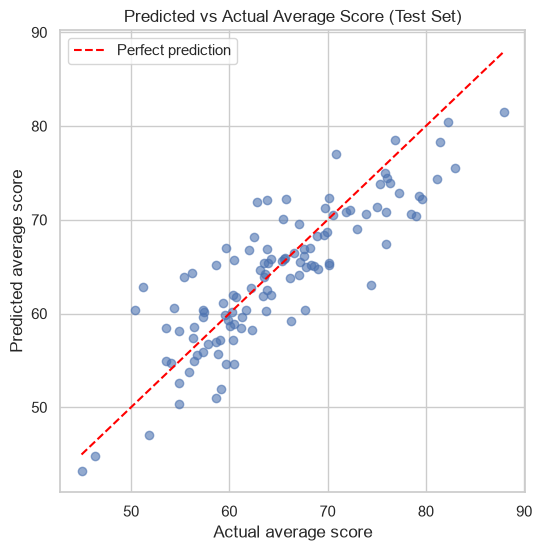

In [35]:
plt.figure(figsize=(6, 6))
plt.scatter(y_test, eng_pred, alpha=0.6)
axis_min, axis_max = y_test.min(), y_test.max()
plt.plot([axis_min, axis_max], [axis_min, axis_max], color="red", linestyle="--", label="Perfect prediction")
plt.title("Predicted vs Actual Average Score (Test Set)")
plt.xlabel("Actual average score")
plt.ylabel("Predicted average score")
plt.legend()
plt.savefig("charts/10_predicted_vs_actual.png", dpi=150, bbox_inches="tight")
plt.show()

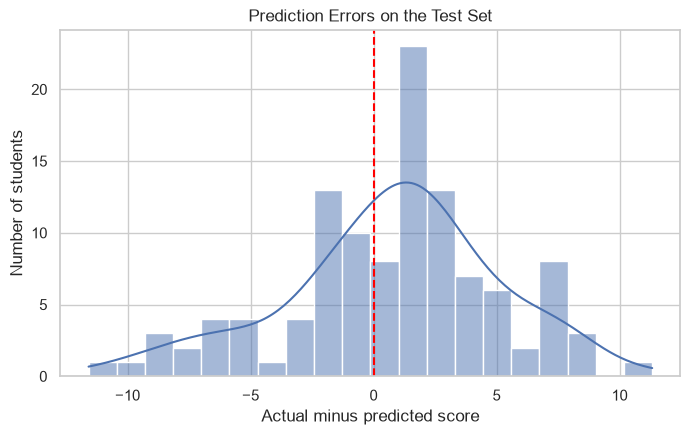

Mean error: 0.72
Largest overestimate (predicted too high by): 11.58
Largest underestimate (predicted too low by): 11.33


In [36]:
residuals = y_test - eng_pred

plt.figure(figsize=(8, 4.5))
sns.histplot(residuals, bins=20, kde=True)
plt.axvline(0, color="red", linestyle="--")
plt.title("Prediction Errors on the Test Set")
plt.xlabel("Actual minus predicted score")
plt.ylabel("Number of students")
plt.savefig("charts/11_residuals.png", dpi=150, bbox_inches="tight")
plt.show()

print("Mean error:", round(residuals.mean(), 2))
print("Largest overestimate (predicted too high by):", round(-residuals.min(), 2))
print("Largest underestimate (predicted too low by):", round(residuals.max(), 2))

In [37]:
# how well would the model flag students who are genuinely at risk?
actual_risk = y_test < AT_RISK_BELOW
predicted_risk = eng_pred < AT_RISK_BELOW

caught = int((actual_risk & predicted_risk).sum())
missed = int((actual_risk & ~predicted_risk).sum())
false_alarms = int((~actual_risk & predicted_risk).sum())

print("Genuinely at-risk students in the test set:", int(actual_risk.sum()))
print("Correctly flagged:", caught)
print("Missed:", missed)
print("False alarms:", false_alarms)

Genuinely at-risk students in the test set: 12
Correctly flagged: 7
Missed: 5
False alarms: 6


## 11. Conclusions

- Previous score, study hours and attendance are all positively related to performance, and the three are nearly independent of each other.
- Attendance matters more at the low end: the score gain per attendance point is roughly 0.8 below 65% against 0.3 above it.
- Study time shows diminishing returns, so the first extra hours matter most.
- Maths is the weakest subject for the whole group, and the one where study time matters most.
- A simple linear model explains about 72% of the variation in average score on unseen students, with an average error of 3.4 points.

**Limitations.** The data is synthetic, and the patterns were built into it, so these are demonstrations of method and not findings about real students. The model is linear, so it cannot capture interactions. The test set is small (114 students), so the figures would move with a different split. Missing values were filled before splitting. The at-risk flagging is weak. Correlation does not show cause.

**Next steps.** Repeat the workflow on a real student dataset, try tree-based models, and treat at-risk detection as a classification problem with its own evaluation.